In [4]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_dir = Path("../model_for_mel_by_sites/models")

In [24]:
rows = []

for result_path in results_dir.glob("*/results.json"):
    run_dir = result_path.parent
    with open(result_path, "r", encoding="utf-8") as f:
        result = json.load(f)

    train_site = result["train_site"]
    train_site_name = result["train_site_name"]

    for test_site, test_result in result["site_test_results"].items():
        pause_path = run_dir / f"evaluation_test_{test_site}" / "pause_data.json"

        with open(pause_path, "r", encoding="utf-8") as f:
            pause_data = json.load(f)

        rows.append({
            "train": train_site,
            "train_name": train_site_name,
            "test": test_site,
            "test_name": test_result["test_site_name"],
            "accuracy_without_pause": pause_data["accuracy_without_pause"],
            "num_train_samples": result["num_train_samples"],
            "num_test_samples": test_result["num_test_samples"]
        })

df = pd.DataFrame(rows)

print("All site-transfer results:")
print(df.to_string(index=False, formatters={"accuracy_without_pause": "{:.4f}".format}))

All site-transfer results:
train train_name test test_name accuracy_without_pause  num_train_samples  num_test_samples
    D     Munich    A      Kiel                 0.2817            1660646            216520
    D     Munich    N      Bonn                 0.2932            1660646            610429
    D     Munich    D    Munich                 0.3000            1660646            382331
    N       Bonn    A      Kiel                 0.2776            1086887            216520
    N       Bonn    N      Bonn                 0.2985            1086887            610429
    N       Bonn    D    Munich                 0.2783            1086887            382331
    A       Kiel    A      Kiel                 0.2949            1319069            216520
    A       Kiel    N      Bonn                 0.2984            1319069            610429
    A       Kiel    D    Munich                 0.2849            1319069            382331


In [21]:
accuracy_matrix = df.pivot(index="train", columns="test", values="accuracy_without_pause")

site_order = ["A", "N", "D"]
accuracy_matrix = accuracy_matrix.loc[site_order, site_order]

print("Accuracy matrix:")
print(accuracy_matrix.round(4))

Accuracy matrix:
test        A       N       D
train                        
A      0.2949  0.2984  0.2849
N      0.2776  0.2985  0.2783
D      0.2817  0.2932  0.3000


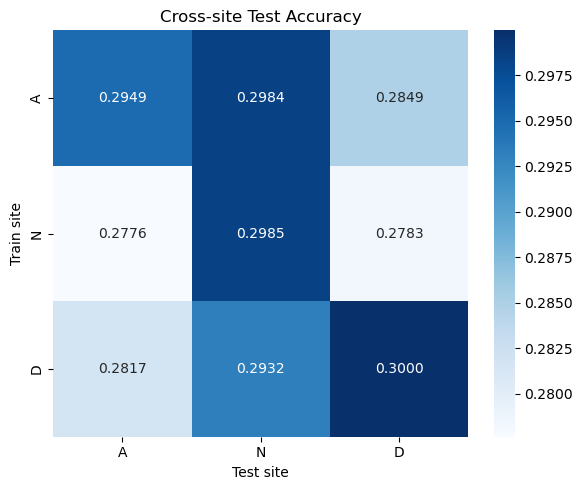

In [26]:
plt.figure(figsize=(6, 5))

sns.heatmap(accuracy_matrix, annot=True, fmt=".4f", cmap="Blues")

plt.title("Cross-site Test Accuracy")
plt.xlabel("Test site")
plt.ylabel("Train site")

plt.savefig("mel_site_transfer_accuracy.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()